**Comparación de iteraciones (Método de la sección áurea), con convergencia en n = 15 iteraciones para una tolerancia de epsilon = 50:**

|   $n$ |   $x_l$ |   $x_u$ |   $T_{max}$ |   $\vert{x_u - x_l}\vert$ |
|------:|--------:|--------:|------------:|--------------------------:|
|     0 |  3000   | 50000   |     26500   |                47000      |
|     1 | 20952.4 | 50000   |     35476.2 |                29047.6    |
|     2 | 20952.4 | 38904.8 |     29928.6 |                17952.4    |
|     3 | 27809.6 | 38904.8 |     33357.2 |                11095.2    |
|     4 | 27809.6 | 34666.8 |     31238.2 |                 6857.21   |
|     5 | 27809.6 | 32047.6 |     29928.6 |                 4237.99   |
|     6 | 29428.4 | 32047.6 |     30738   |                 2619.22   |
|     7 | 30428.8 | 32047.6 |     31238.2 |                 1618.77   |
|     8 | 30428.8 | 31429.3 |     30929.1 |                 1000.45   |
|     9 | 30428.8 | 31047.1 |     30738   |                  618.314  |
|    10 | 30665   | 31047.1 |     30856.1 |                  382.139  |
|    11 | 30665   | 30901.2 |     30783.1 |                  236.175  |
|    12 | 30755.2 | 30901.2 |     30828.2 |                  145.964  |
|    13 | 30755.2 | 30845.4 |     30800.3 |                   90.2108 |
|    14 | 30755.2 | 30811   |     30783.1 |                   55.7533 |
|    15 | 30776.5 | 30811   |     30793.7 |                   34.4575 |

El método converge en T_max = 30793.74070 K con una potencia de P(T_max) = 3.51402e+08 W/m^2.


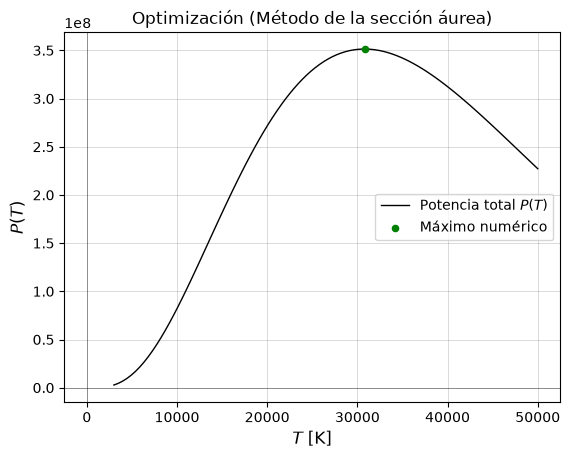

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

# Optimización: Sección Áurea (Temperatura de emisión estelar)

sigma = 5.67e-8 # W * m^-2 * K^-4
T0 = 1e4 # K
hv_kb = 5e3 # K 

def P(T):
    return sigma * T**4 * np.exp(-T/T0) * (1 - np.exp(-hv_kb/T))

# Parámetros de solución:

epsilon = 50
x_start = [3e3, 5e4]

def optimization_gold(x_start, f, table=True):

    i_table = []
    counter = 0
    R = (np.sqrt(5) - 1)/2

    xl, xu = x_start[0], x_start[1]
    xmax = (xl + xu)/2

    d  = (np.sqrt(5) - 1)*(xu - xl)/2
    x1 = xl + d
    x2 = xu - d
    f1, f2 = f(x1), f(x2)

    i_table.append({
        '$n$'  : counter,
        '$x_l$': round(xl, 5),
        '$x_u$': round(xu, 5),
        '$T_{max}$': round(xmax, 5),
        '$\\vert{x_u - x_l}\\vert$' : round(abs(xu-xl), 5)
    })

    while abs(xu - xl) >= epsilon:
        if f1 > f2: 
            xl = x2
            x2 = x1
            f2 = f1  
            x1 = xl + R * (xu - xl)
            f1 = f(x1)  
        else:        
            xu = x1
            x1 = x2
            f1 = f2 
            x2 = xu - R * (xu - xl)
            f2 = f(x2)  

        counter += 1
        xmax = (xl + xu)/2

        i_table.append({
            '$n$'  : counter,
            '$x_l$': round(xl, 5),
            '$x_u$': round(xu, 5),
            '$T_{max}$': round(xmax, 5),
            '$\\vert{x_u - x_l}\\vert$' : round(abs(xu-xl), 5)
        })

    if table:
        df_tabla = f"**Comparación de iteraciones (Método de la sección áurea), con convergencia en n = {counter} iteraciones para una tolerancia de epsilon = {epsilon}:**\n\n" + pd.DataFrame(i_table).to_markdown(index=False)
        display(Markdown(df_tabla))

    return xmax, counter

xmax, counter = optimization_gold(x_start, P)
Pmax = P(xmax)
x = np.linspace(x_start[0], x_start[1], 100)

print(f'El método converge en T_max = {xmax:.5f} K con una potencia de P(T_max) = {Pmax:.5e} W/m^2.')

plt.plot(x, P(x), color='k', linewidth=1, label='Potencia total $P(T)$')
plt.scatter(xmax, Pmax, color='g', s=20, zorder=3, label='Máximo numérico')

plt.xlabel('$T$ [K]', fontsize=12)
plt.axhline(y=0, color='k', linewidth=0.5, alpha=0.5)
plt.ylabel('$P(T)$', fontsize=12)
plt.axvline(x=0, color='k', linewidth=0.5, alpha=0.5)
plt.title('Optimización (Método de la sección áurea)', fontsize=12)
plt.grid(color='k', linewidth=0.5, alpha=0.2)
plt.legend()
plt.show()